# Manuscript:   A reference map of CDK-cyclin dependencies across human cancers
# Project:      Codependencies
# Part:         G. Validation
# Author:       Agustín Sánchez-Belmonte
# Date:         04/09/23
# Last update:  08/02/26

# Validation CODEPENDENCIES

## Import modules

In [ ]:
import os
import re
import pandas as pd
import numpy as np
import scipy.sparse as sp

import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns

import anndata as ad
import scanpy as sc

import gseapy as gspy


In [228]:

sc.set_figure_params(dpi_save=300)

## Predicted clusters

In [ ]:
# feline 50

#Cargar top markers
marker_table = pd.read_csv("Supplementary_tables/TableS11_DepMap_Breast_Cluster_markers.csv", sep=";", index_col=0)

# Crear diccionario cluster → lista de genes
cluster_genes = {col: marker_table[col].dropna().tolist() for col in marker_table.columns}

In [145]:
# cell lines 20 

# Crear un nuevo diccionario solo con los primeros 20 genes de cada grupo
cluster_genes = {cluster: genes[:20] for cluster, genes in cluster_genes.items()}

# Comprobación rápida del conteo
for cluster, genes in cluster_genes.items():
    print(f"Grupo {cluster}: {len(genes)} genes seleccionados.")

Grupo A: 20 genes seleccionados.
Grupo C: 20 genes seleccionados.
Grupo D: 20 genes seleccionados.
Grupo F: 20 genes seleccionados.


In [315]:
cluster_genes

{'A': ['TFF1',
  'TFF3',
  'ELAPOR1',
  'DEGS2',
  'CA12',
  'AGR2',
  'XBP1',
  'AGR3',
  'GHR',
  'GPR160',
  'SPDEF',
  'CMBL',
  'FOXA1',
  'PRODH',
  'AR',
  'GATA3',
  'THSD4',
  'ANXA9',
  'GREB1',
  'IGFBP2',
  'STARD10',
  'HGD',
  'ENPP1',
  'NCAM2',
  'SCGB2A2',
  'SLC40A1',
  'ZG16B',
  'RHOB',
  'DEPTOR',
  'SPTSSB',
  'LIN7A',
  'SIDT1',
  'CRYM',
  'RHOH',
  'C5AR2',
  'HMGCS2',
  'PRRT1B',
  'ESR1',
  'DCDC2',
  'TTC39A',
  'TOX3',
  'LARGE1',
  'RET',
  'ABCC11',
  'ABAT',
  'SCGB1D2',
  'LMX1B',
  'HID1',
  'ZNF703',
  'C9orf152'],
 'C': ['PRAC2',
  'PSTK',
  'CUZD1',
  'PCDH8',
  'H3Y1',
  'C10orf88',
  'MMP20',
  'CCL3L3',
  'OR3A2',
  'PGK2',
  'FAM24A',
  'TRIM43',
  'TAF11L12',
  'TAF11L14',
  'SKAP1',
  'TAF11L11',
  'ACTA1',
  'TRIM49B',
  'TRIM49',
  'TRIM43B',
  'CNTN5',
  'TAF11L13',
  'IKZF5',
  'HHLA1',
  'TMEM179',
  'CT45A9',
  'SSU72L4',
  'TRIM49D2',
  'MBD3L2',
  'OC90',
  'LRRTM4',
  'NPVF',
  'SSU72L6',
  'AKAP9',
  'NEFH',
  'COL11A2',
  'FAM24B',


# GSE150997

In [ ]:
adata = sc.read_h5ad("Downloads/GSE150997_scRNAseq.h5ad")

In [231]:
adata.obs

,Group,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,n_genes
GSM4563845,MCF7-EDR/PalboR,23167,10.050527,25783902.0,17.065262,17.537043,22.449030,28.697856,39.756527,0.0,0.0,0.0,23167
GSM4563846,MCF7-EDR/PalboR,22823,10.035568,21857532.0,16.900057,17.579766,22.510725,28.634884,39.594164,0.0,0.0,0.0,22823
GSM4563847,MCF7-EDR,22473,10.020114,24980842.0,17.033619,15.214355,20.401190,27.211913,39.074832,0.0,0.0,0.0,22473
GSM4563848,MCF7-EDR,21912,9.994835,19258686.0,16.773474,14.989392,20.332867,27.105572,38.912224,0.0,0.0,0.0,21912
GSM4563849,MCF7-FulR,23289,10.055779,27186688.0,17.118238,12.604308,17.622327,23.648243,34.932192,0.0,0.0,0.0,23289
GSM4563850,MCF7-FulR,23470,10.063521,29957872.0,17.215303,12.568406,17.413527,23.422061,34.741219,0.0,0.0,0.0,23470
GSM4563851,MCF7-P/PalboR,22374,10.015700,14191844.0,16.468178,17.694748,22.637855,29.139645,40.526721,0.0,0.0,0.0,22374
GSM4563852,MCF7-P/PalboR,22155,10.005864,12426325.0,16.335327,18.200055,23.097778,29.421868,40.737507,0.0,0.0,0.0,22155
GSM4563853,MCF7-P,22620,10.026634,26603336.0,17.096548,14.195558,19.084783,25.706716,37.107955,0.0,0.0,0.0,22620
GSM4563854,MCF7-P,22894,10.038674,29543040.0,17.201359,13.760175,18.579645,25.093176,36.467889,0.0,0.0,0.0,22894


In [ ]:
# 1. Calculate genes
for cluster_name, genes in cluster_genes.items():
    genes_in_data = [g for g in genes if g in adata.var_names]
    
    if len(genes_in_data) > 0:
        sc.tl.score_genes(adata, gene_list=genes_in_data, score_name=cluster_name)
    else:
        print(f"No genes {cluster_name}")

names_to_extract = [k for k in cluster_genes.keys() if k in adata.obs.columns]

# 3. Clasify
adata.obs['predicted_cluster'] = adata.obs[names_to_extract].idxmax(axis=1)

# 4. Margin
sorted_scores = adata.obs[names_to_extract].values.copy()
sorted_scores.sort(axis=1)
adata.obs['classification_margin'] = sorted_scores[:, -1] - sorted_scores[:, -2]

# --- verify ---
print(adata.obs[['predicted_cluster', 'classification_margin'] + names_to_extract].head())

           predicted_cluster  classification_margin         A         C  \
GSM4563845                 A               0.836897  0.718051 -0.731835   
GSM4563846                 A               0.804691  0.719050 -0.427583   
GSM4563847                 A               2.119552  1.478199 -0.641354   
GSM4563848                 A               2.034497  1.554362 -0.539842   
GSM4563849                 A               0.314026  0.319013  0.004988   

                   D         F  
GSM4563845 -0.118846 -0.605107  
GSM4563846 -0.085641 -0.507556  
GSM4563847 -0.648369 -0.724177  
GSM4563848 -0.480134 -0.725195  
GSM4563849 -0.104028 -0.220909  


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cu

In [234]:
adata.obs['predicted_cluster'].value_counts()

A    25
F     8
Name: predicted_cluster, dtype: int64

In [235]:
order = ['T47D-P_LM','T47D-EDR','T47D-TamR','T47D-FulR','T47D-P/PalboR_LM','T47D-EDR/PalboR',
    'MCF7-P','MCF7-EDR','MCF7-TamR','MCF7-FulR','MCF7-P/PalboR','MCF7-EDR/PalboR',
         'ZR75-1-P','ZR75-1-EDR','ZR75-1-TamR','ZR75-1-FulR']


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'predicted_cluster' as categorical


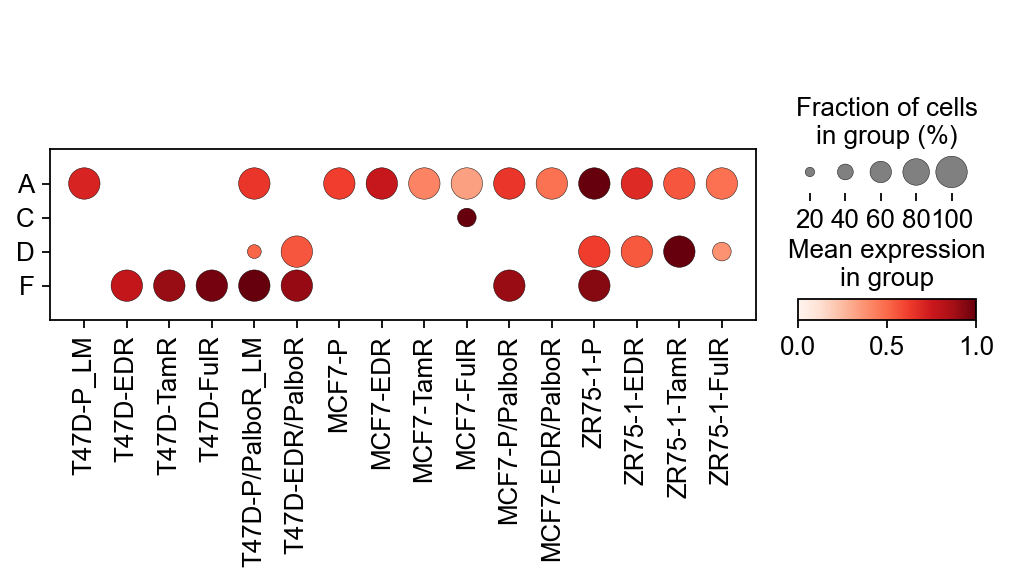

In [236]:
variables = ['A','C','D','F']
sc.pl.dotplot(
    adata,
    var_names=variables,
    groupby="Group",swap_axes=True, 
    categories_order= order,
    gene_symbols=None,
    save="_dotplot_cdkpredict.png", standard_scale='var'
)

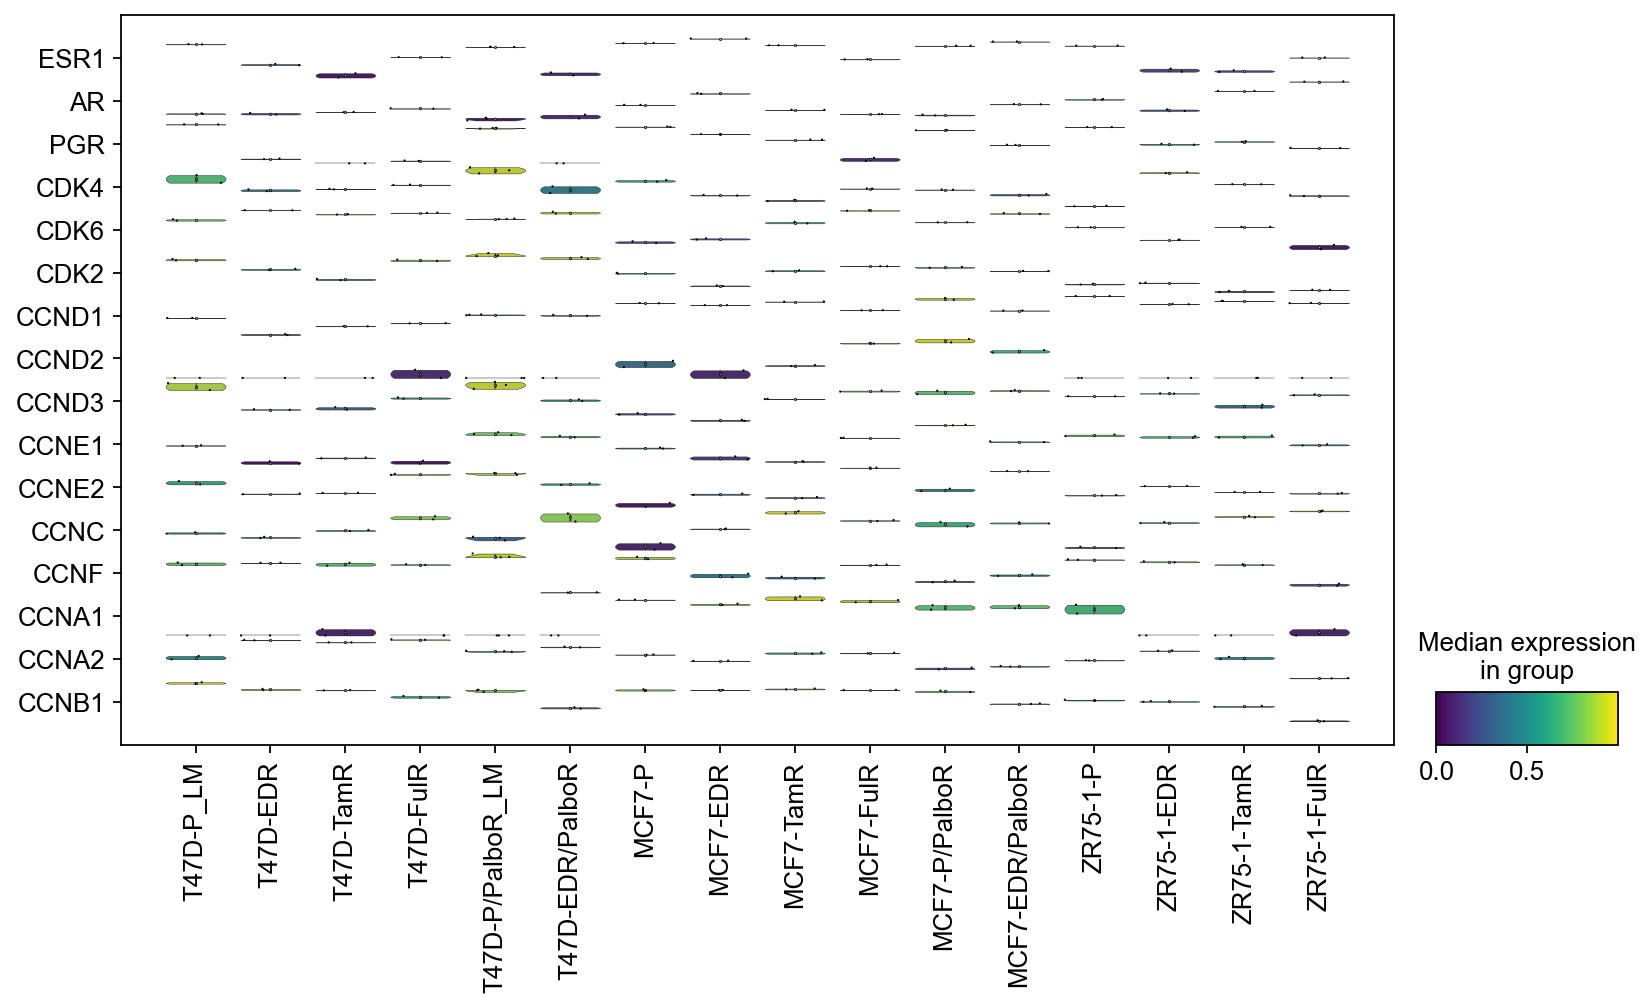

In [ ]:

genes_interes = [
    'ESR1', 'AR', 'PGR',                   
    'CDK4', 'CDK6', 'CDK2',                 
    'CCND1', 'CCND2', 'CCND3',              
    'CCNE1', 'CCNE2',                     
    'CCNC', 'CCNF',                         
    'CCNA1', 'CCNA2', 'CCNB1'               
]

sc.pl.stacked_violin(
    adata, 
    var_names=genes_interes, 
    groupby='Group', 
    categories_order=order,
    standard_scale='var',
    swap_axes=True,
    inner='boxplot',
    stripplot=True,           
    jitter=0.4,               
    size=1,                   
    ax=None,                  
    cmap='viridis',
    figsize=(12, 6),
    save="_violin_ciclinas_cdk_final.png"
)

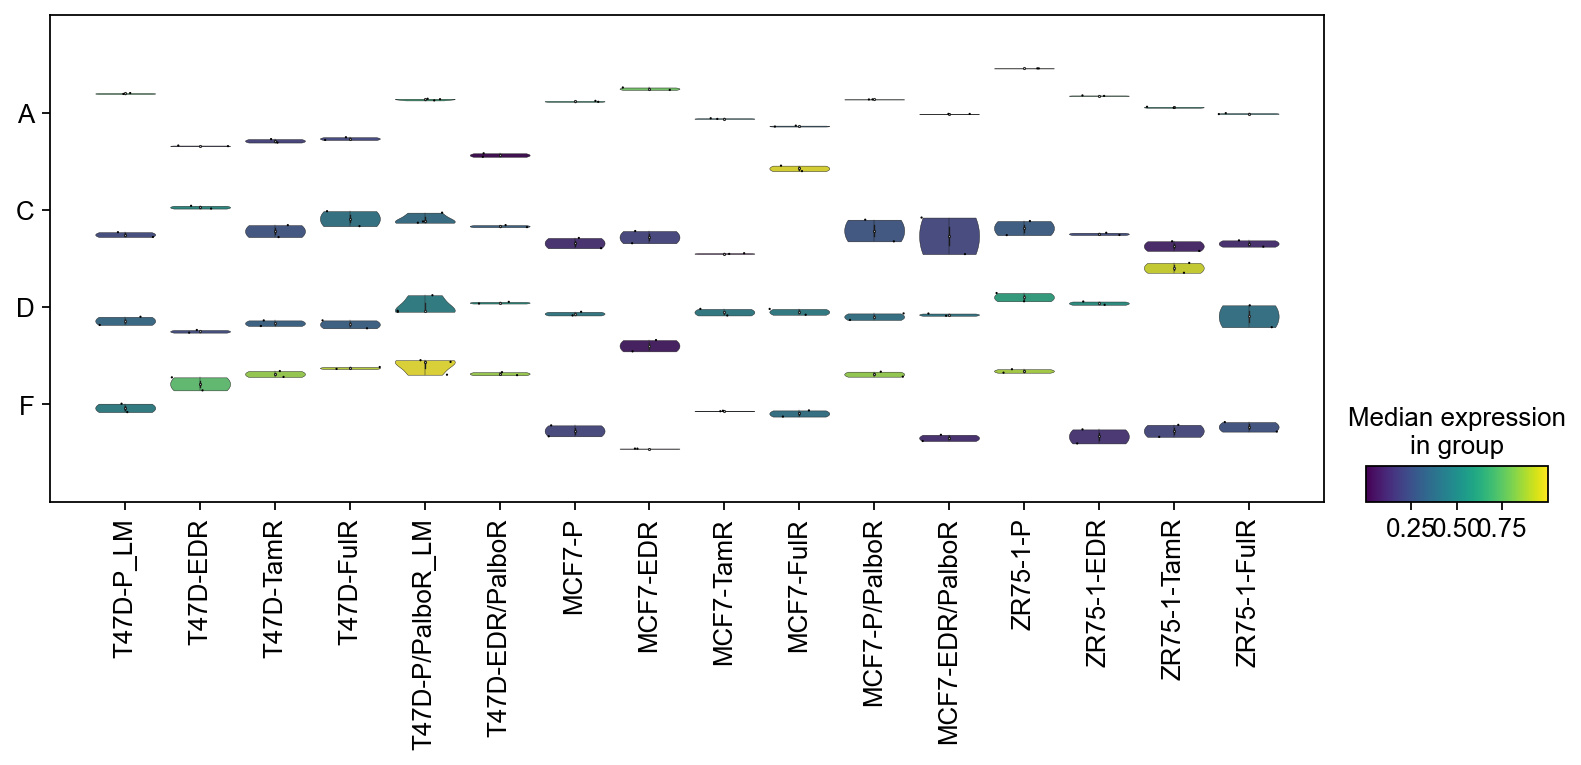

In [ ]:
sc.pl.stacked_violin(
    adata, 
    var_names=variables, 
    groupby='Group', 
    categories_order=order,
    standard_scale='var',
    swap_axes=True,
    inner='boxplot',
    stripplot=True,           
    jitter=0.4,               
    size=1,                   
    ax=None,                  
    cmap='viridis',
    figsize=(12, 6),
    save="_violin_ciclinas_cdk_final.png"
)

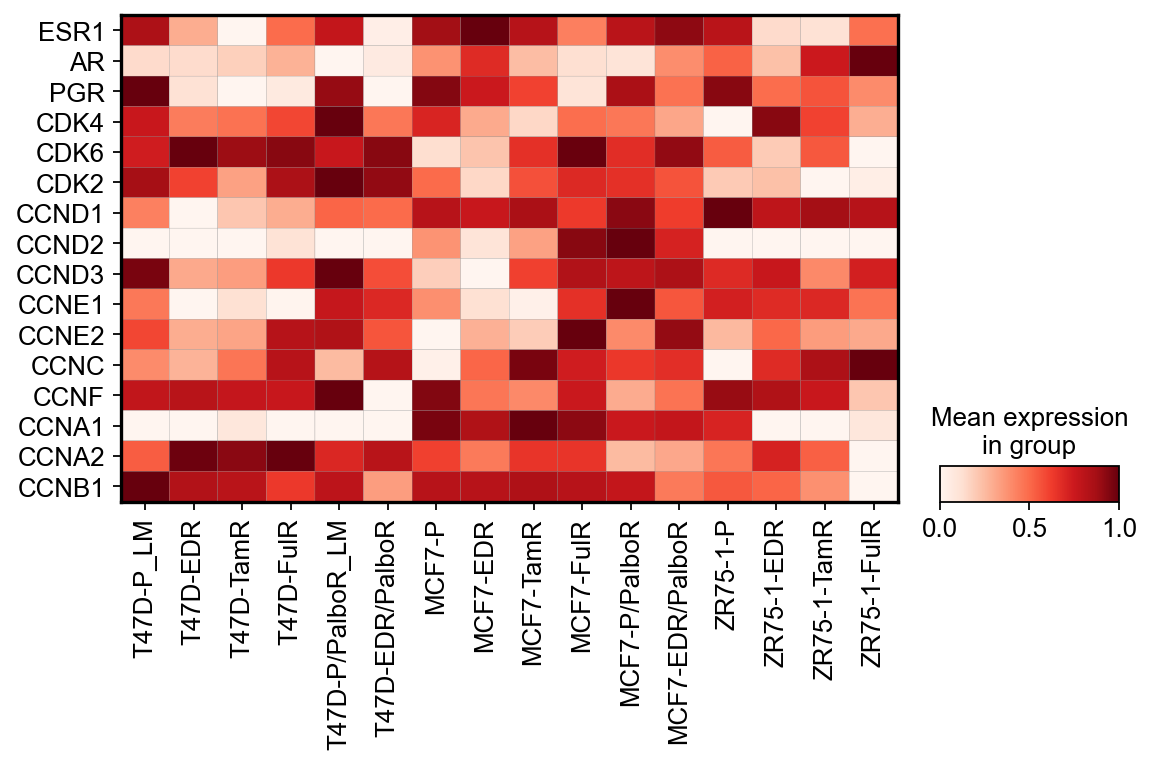

In [ ]:
sc.pl.matrixplot(
    adata, 
    var_names=genes_interes, 
    groupby='Group', 
    categories_order=order,
    use_raw=False,
    standard_scale='var', 
    cmap='Reds',
    figsize=(8, 4),
    swap_axes=True,
    save='test.png'
)

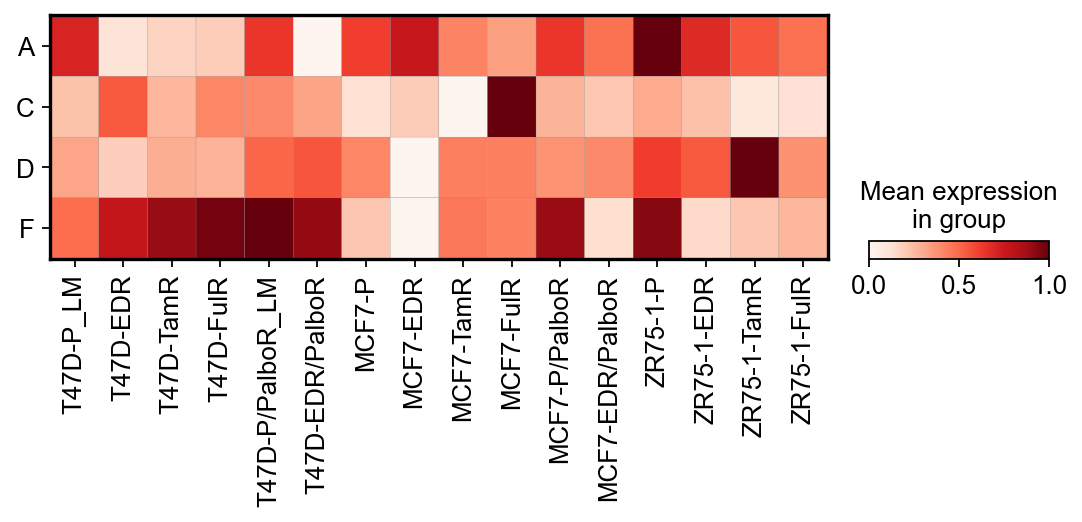

In [ ]:
sc.pl.matrixplot(
    adata, 
    var_names=variables, 
    groupby='Group', 
    categories_order=order,
    use_raw=False,
    standard_scale='var', 
    cmap='Reds',
    figsize=(8, 2),
    swap_axes=True,
    save='test.png'
)

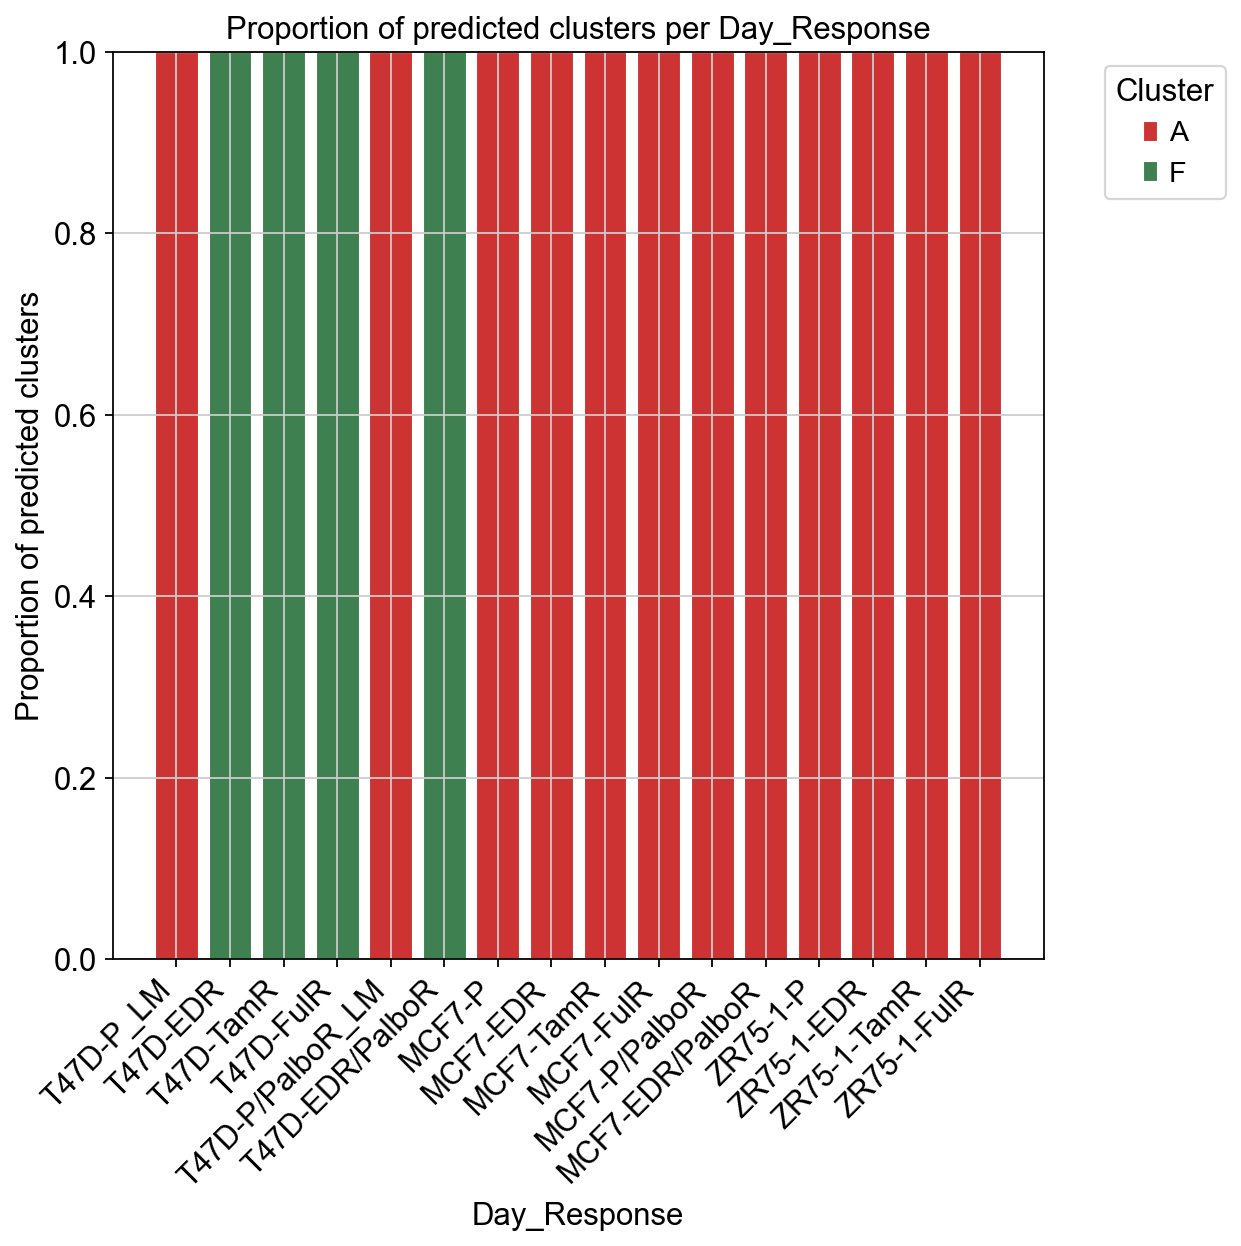

In [ ]:

prop_table = (
    adata.obs
    .groupby(['Group', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

existing_order = [o for o in order if o in prop_table.index]
prop_table = prop_table.reindex(existing_order)

prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)


cluster_colors = {
    "A": "#CD3333",
    #"D": "#7A378B",
    "F": "#3E804F"
}

prop_table = prop_table[list(cluster_colors.keys())]


fig, ax = plt.subplots(figsize=(8, 8))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(
        x, 
        prop_table[cluster], 
        bottom=bottom, 
        color=cluster_colors[cluster], 
        label=cluster,
        edgecolor='white',
        linewidth=0.5
    )
    bottom += prop_table[cluster].values


ax.set_xticks(x)

ax.set_xticklabels(prop_table.index, rotation=45, ha='right') 
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Day_Response") 
ax.set_title("Proportion of predicted clusters per Day_Response")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_ordered.png", dpi=300)
plt.show()

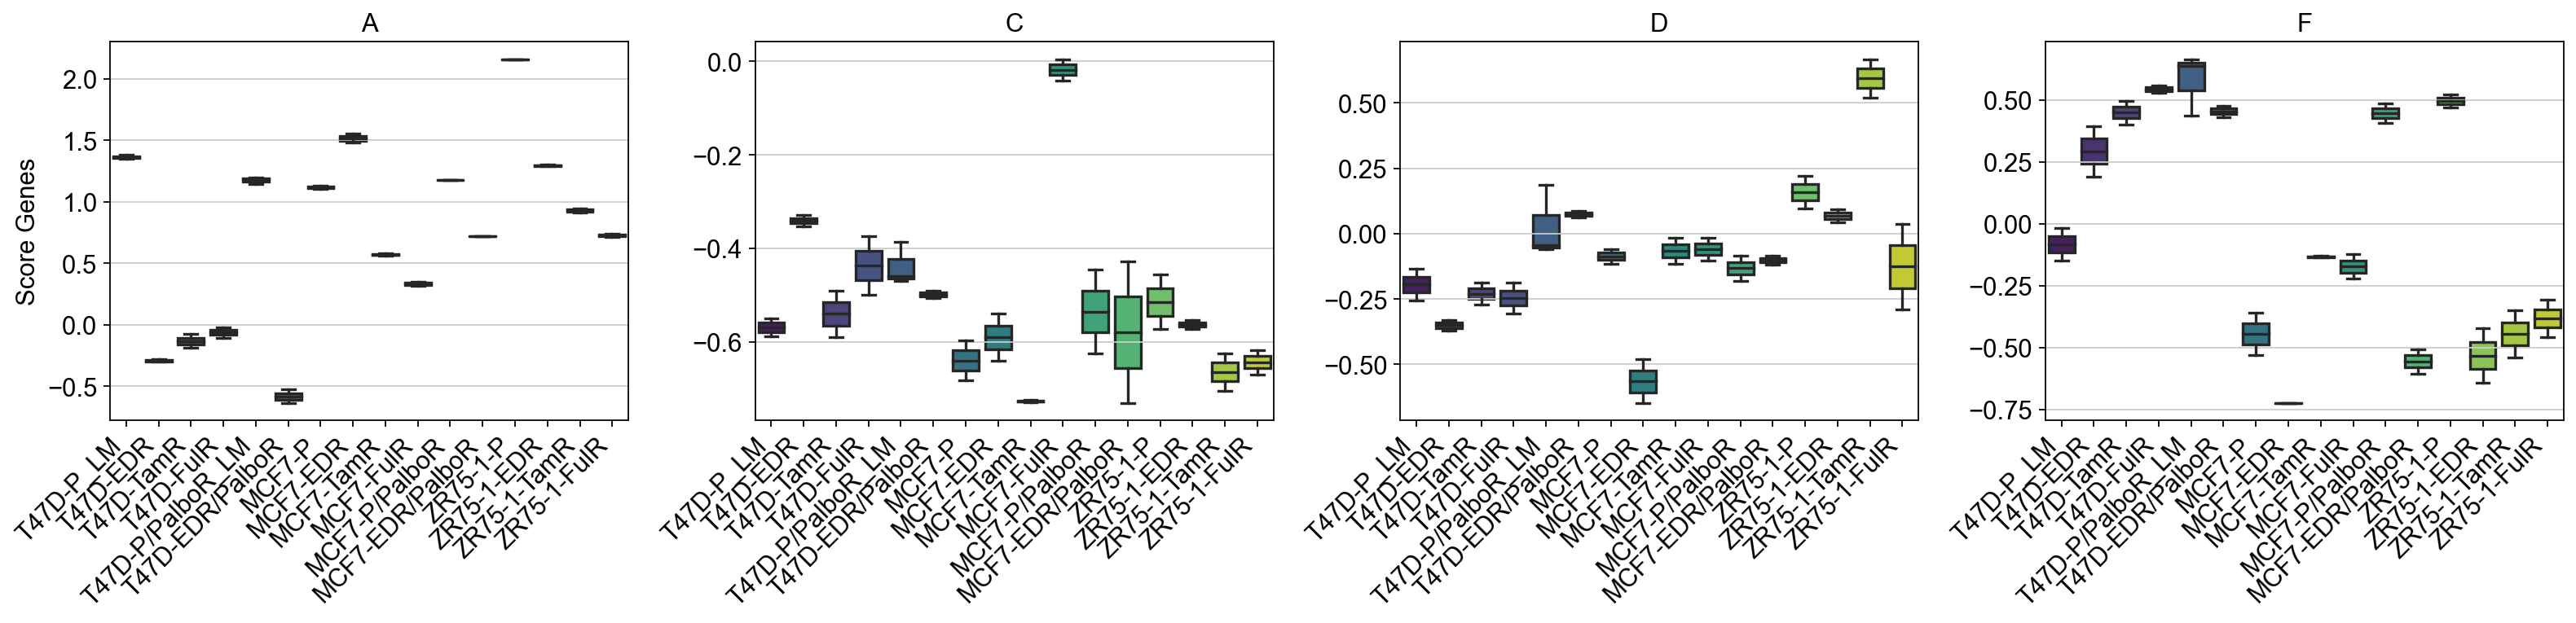

In [ ]:


fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

for i, var in enumerate(variables):
    sns.boxplot(
        data=adata.obs,
        x='Group', 
        y=var,
        order=[o for o in order if o in adata.obs['Group'].unique()],
        ax=axes[i],
        palette='viridis',
        fliersize=2  
    )
    axes[i].set_title(f'{var}', fontsize=14)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Score Genes' if i==0 else '')

plt.tight_layout()
plt.savefig("boxplots_individuales_firmas.png", dpi=300)
plt.show()

# GSE222367

In [ ]:
adata = sc.read_h5ad("Downloads/GSE222367_scRNAseq.h5ad")

In [245]:
adata.obs

,Group,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,n_genes
GSM6921637,MCF7,23748,10.075296,18773842.0,16.747974,19.539724,25.370081,31.988029,43.376699,0.0,0.0,0.0,23748
GSM6921638,MCF7,22605,10.025971,24212864.0,17.002394,25.658088,30.926317,37.598105,48.861758,0.0,0.0,0.0,22605
GSM6921639,MCF7,21521,9.976831,23177296.0,16.958683,20.333006,26.170844,32.897867,43.618009,0.0,0.0,0.0,21521
GSM6921640,MCF7_1_2_P,19528,9.879656,32507600.0,17.296984,28.846371,37.621439,47.405013,60.894169,0.0,0.0,0.0,19528
GSM6921641,MCF7_1_2_P,18940,9.849084,25646422.0,17.059916,39.470360,46.102883,53.296121,64.049640,0.0,0.0,0.0,18940
GSM6921642,MCF7_1_2_P,21091,9.956649,17636864.0,16.685501,32.150840,38.540344,45.625005,55.693694,0.0,0.0,0.0,21091
GSM6921644,MCF7_2_4_P,21754,9.987599,25101964.0,17.038456,25.512920,32.793530,41.294566,53.559698,0.0,0.0,0.0,21754
GSM6921645,MCF7_2_4_P,20967,9.950753,22606768.0,16.933760,21.110851,27.976109,36.059423,47.700538,0.0,0.0,0.0,20967
GSM6921646,MCF7_3_6_P,20738,9.939771,28954888.0,17.181250,22.106779,29.774997,39.028156,53.210881,0.0,0.0,0.0,20738
GSM6921647,MCF7_3_6_P,20521,9.929253,24208344.0,17.002209,19.355826,26.105123,33.950170,46.070454,0.0,0.0,0.0,20521


In [ ]:
# 1. Calculate genes
for cluster_name, genes in cluster_genes.items():
    genes_in_data = [g for g in genes if g in adata.var_names]
    
    if len(genes_in_data) > 0:
        sc.tl.score_genes(adata, gene_list=genes_in_data, score_name=cluster_name)
    else:
        print(f"No genes {cluster_name}")

names_to_extract = [k for k in cluster_genes.keys() if k in adata.obs.columns]

# 3. Clasify
adata.obs['predicted_cluster'] = adata.obs[names_to_extract].idxmax(axis=1)

# 4. Margin
sorted_scores = adata.obs[names_to_extract].values.copy()
sorted_scores.sort(axis=1)
adata.obs['classification_margin'] = sorted_scores[:, -1] - sorted_scores[:, -2]

# --- verify ---
print(adata.obs[['predicted_cluster', 'classification_margin'] + names_to_extract].head())

           predicted_cluster  classification_margin         A         C  \
GSM6921637                 A               2.714701  2.387233 -0.327468   
GSM6921638                 A               2.399140  2.171335 -0.227805   
GSM6921639                 A               2.609389  2.280940 -0.328449   
GSM6921640                 F               0.228494 -0.760117 -0.448173   
GSM6921641                 F               0.722612 -0.964656 -0.746725   

                   D         F  
GSM6921637 -0.678563 -1.791599  
GSM6921638 -0.669733 -2.487092  
GSM6921639 -1.019563 -2.295032  
GSM6921640  0.716521  0.945015  
GSM6921641  0.456502  1.179114  


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cu

In [247]:
adata.obs['predicted_cluster'].value_counts()

F    22
A    18
Name: predicted_cluster, dtype: int64

In [248]:
order = ['T47D','T47D_1_2_P','T47D_2_4_P','T47D_3_6_P','T47D_4_8_P',
         'MCF7','MCF7_1_2_P','MCF7_2_4_P','MCF7_3_6_P','MCF7_4_8_P',
         'MCF7_0_5_A','MCF7_1_A','MCF7_1_5_A',]


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'predicted_cluster' as categorical


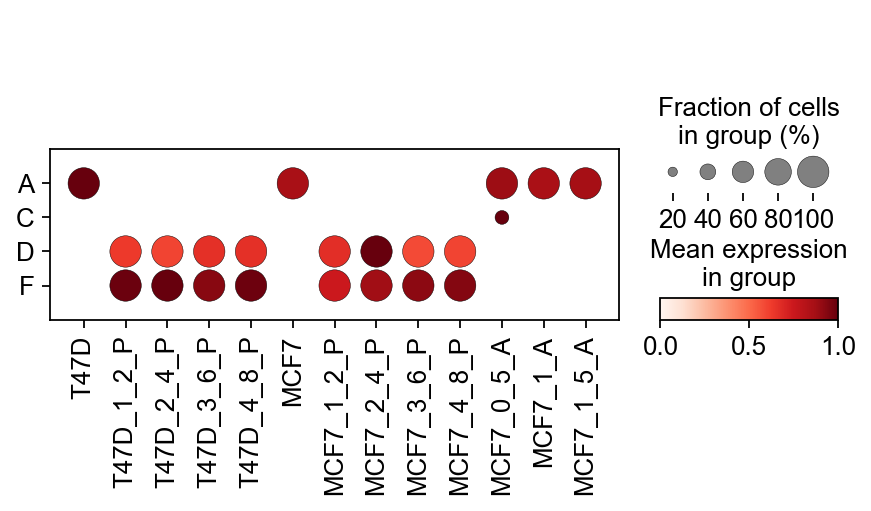

In [249]:
variables = ['A','C','D','F']
sc.pl.dotplot(
    adata,
    var_names=variables,
    groupby="Group",swap_axes=True, 
    categories_order= order,
    gene_symbols=None,
    save="_dotplot_cdkpredict.png", standard_scale='var'
)

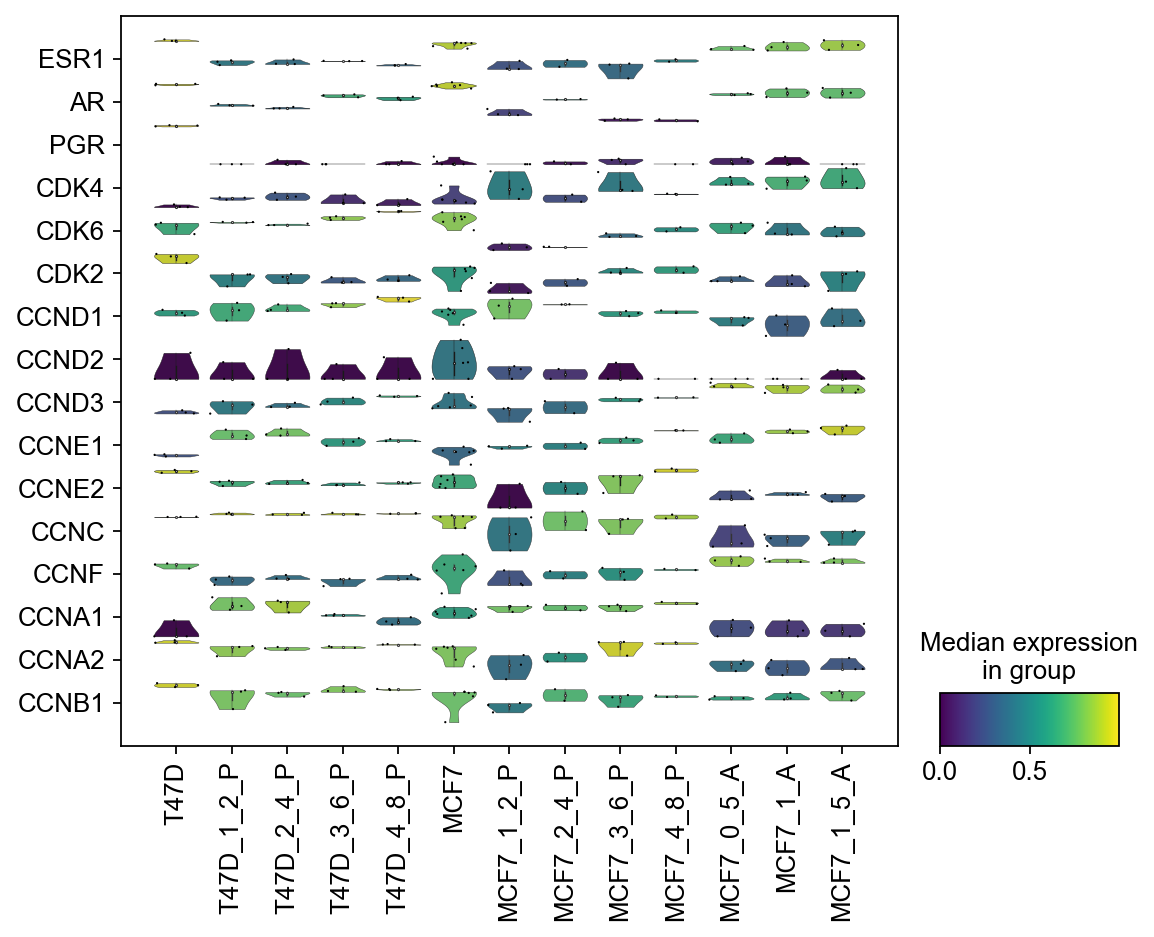

In [ ]:
genes_interes = [
    'ESR1', 'AR', 'PGR',                   
    'CDK4', 'CDK6', 'CDK2',                 
    'CCND1', 'CCND2', 'CCND3',              
    'CCNE1', 'CCNE2',                     
    'CCNC', 'CCNF',                         
    'CCNA1', 'CCNA2', 'CCNB1'               
]

sc.pl.stacked_violin(
    adata, 
    var_names=genes_interes, 
    groupby='Group', 
    categories_order=order,
    standard_scale='var',
    swap_axes=True,
    inner='boxplot',
    stripplot=True,           
    jitter=0.4,               
    size=1,                   
    ax=None,                  
    cmap='viridis',
    figsize=(12, 6),
    save="_violin_ciclinas_cdk_final.png"
)

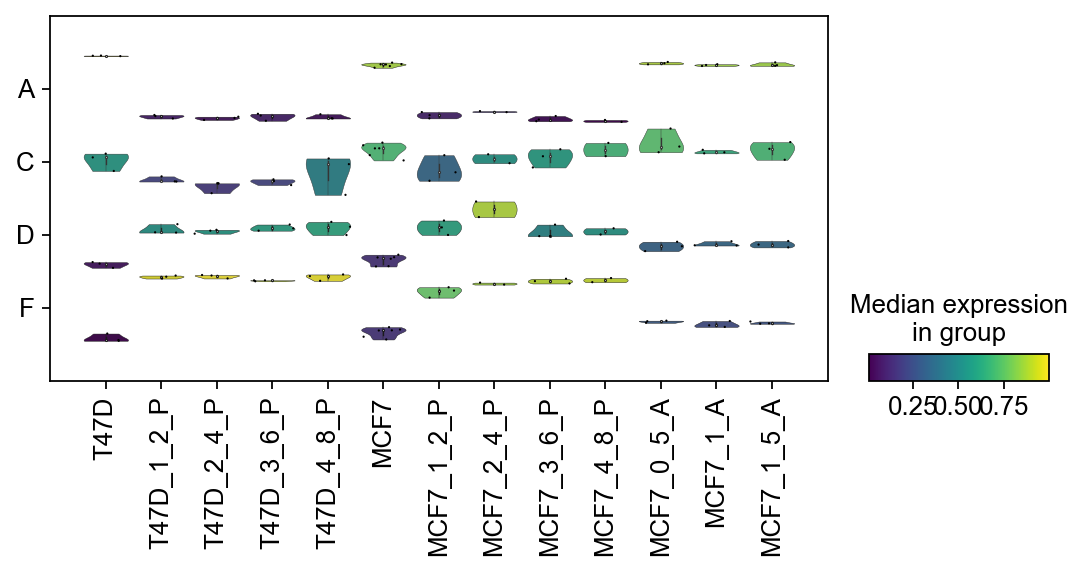

In [ ]:
sc.pl.stacked_violin(
    adata, 
    var_names=variables, 
    groupby='Group', 
    categories_order=order,
    standard_scale='var',
    swap_axes=True,
    inner='boxplot',
    stripplot=True,           
    jitter=0.4,               
    size=1,                   
    ax=None,                  
    cmap='viridis',
    figsize=(12, 6),
    save="_violin_ciclinas_cdk_final.png"
)

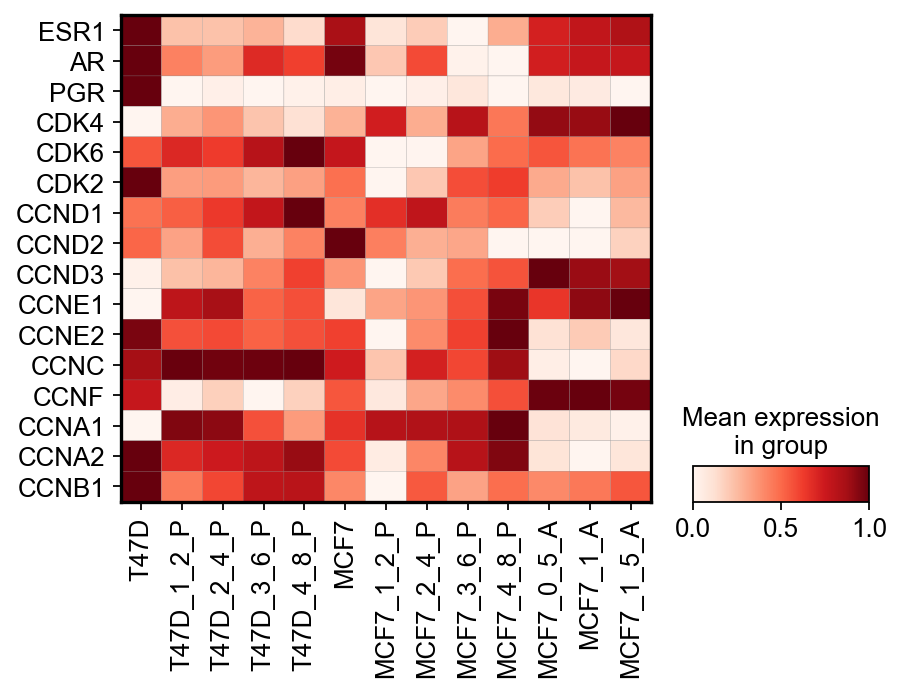

In [ ]:
sc.pl.matrixplot(
    adata, 
    var_names=genes_interes, 
    groupby='Group', 
    categories_order=order,
    use_raw=False,
    standard_scale='var', 
    cmap='Reds',
    figsize=(6, 4),
    swap_axes=True,
    save='test.png'
)

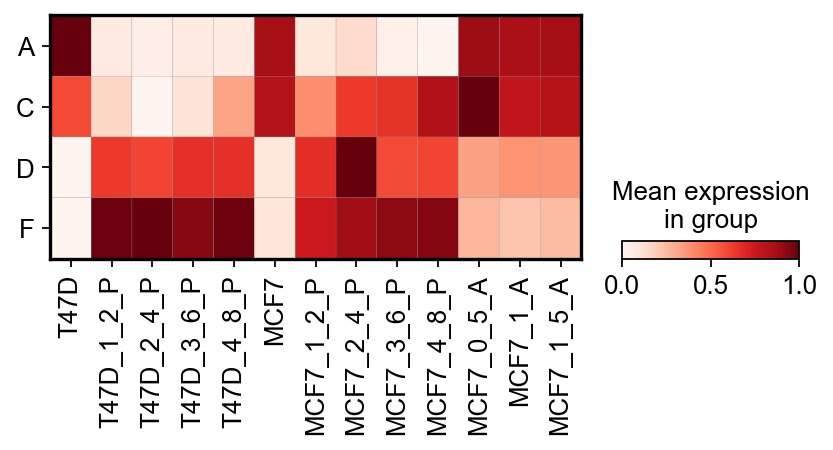

In [ ]:
sc.pl.matrixplot(
    adata, 
    var_names=variables, 
    groupby='Group', 
    categories_order=order,
    use_raw=False,
    standard_scale='var', 
    cmap='Reds',
    figsize=(6, 2),
    swap_axes=True,
    save='test.png'
)

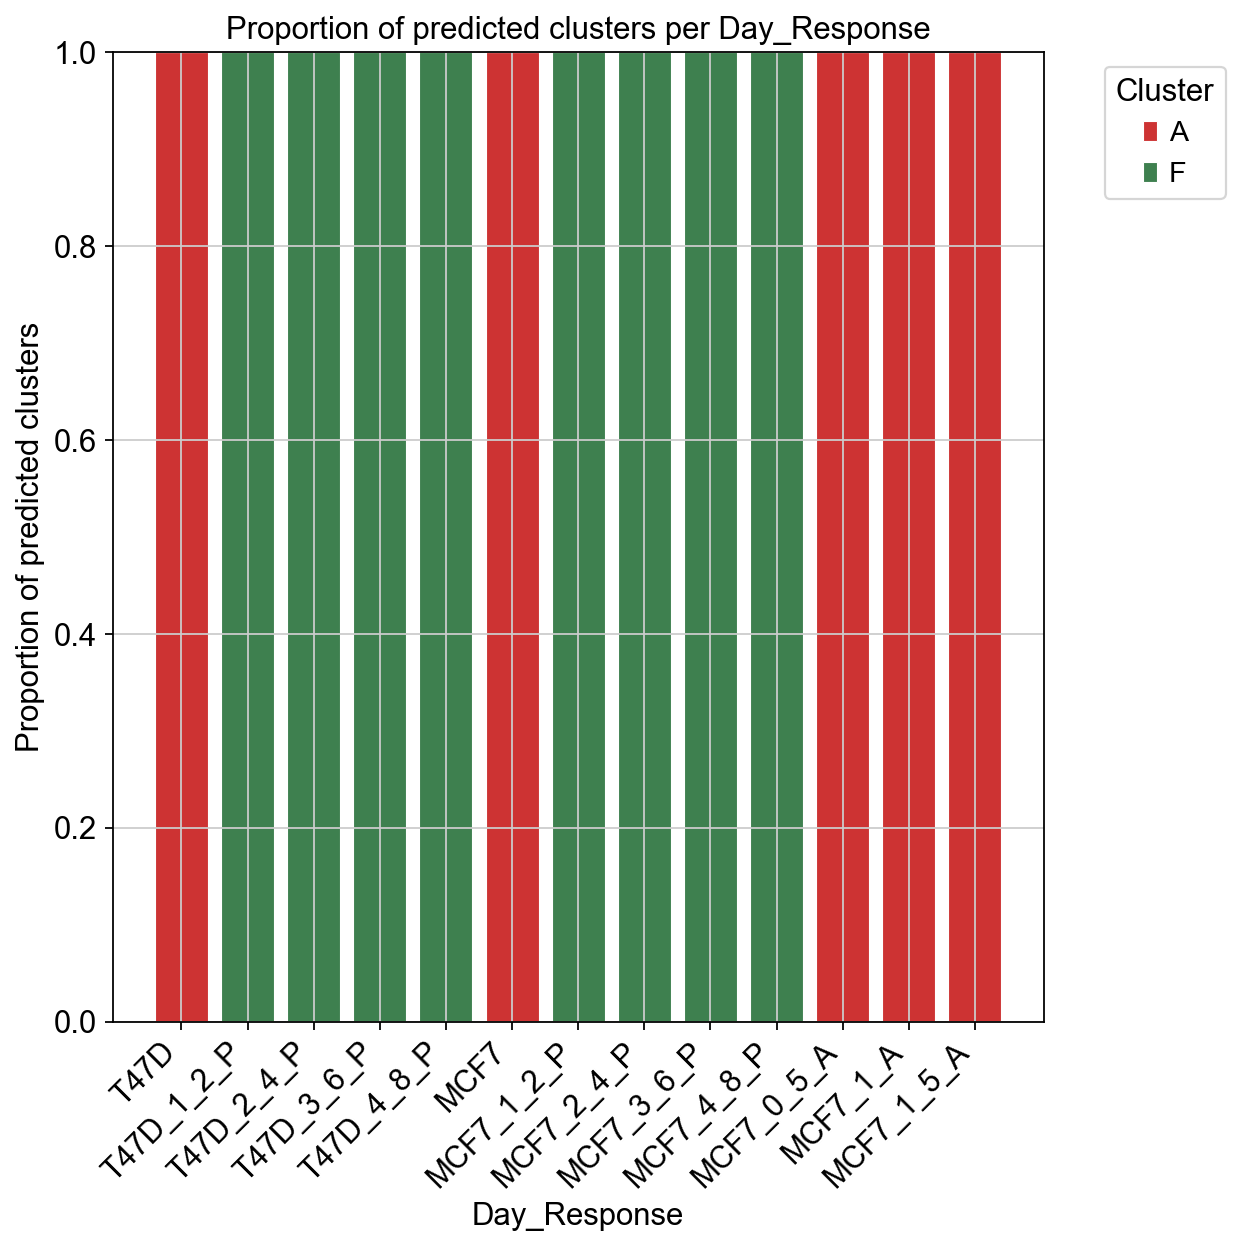

In [ ]:
# --- 1️⃣ Crear tabla de proporciones ---
prop_table = (
    adata.obs
    .groupby(['Group', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

# REORDENAR FILAS: Filtramos el vector order para incluir solo los que existen en la tabla
existing_order = [o for o in order if o in prop_table.index]
prop_table = prop_table.reindex(existing_order)

prop_table = (
    adata.obs
    .groupby(['Group', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

existing_order = [o for o in order if o in prop_table.index]
prop_table = prop_table.reindex(existing_order)

prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)


cluster_colors = {
    "A": "#CD3333",
    #"D": "#7A378B",
    "F": "#3E804F"
}

prop_table = prop_table[list(cluster_colors.keys())]


fig, ax = plt.subplots(figsize=(8, 8))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(
        x, 
        prop_table[cluster], 
        bottom=bottom, 
        color=cluster_colors[cluster], 
        label=cluster,
        edgecolor='white',
        linewidth=0.5
    )
    bottom += prop_table[cluster].values


ax.set_xticks(x)

ax.set_xticklabels(prop_table.index, rotation=45, ha='right') 
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Day_Response") 
ax.set_title("Proportion of predicted clusters per Day_Response")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_ordered.png", dpi=300)
plt.show()
# Convertir a proporción (que cada barra sume 100%)
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# --- 2️⃣ Definir colores para clusters ---
cluster_colors = {
    "A": "#CD3333",
    #"D": "#7A378B",
    "F": "#3E804F"
}

# Ordenar columnas para que coincida con colores (y solo los clusters que definiste)
prop_table = prop_table[list(cluster_colors.keys())]

# --- 3️⃣ Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(8, 8))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(
        x, 
        prop_table[cluster], 
        bottom=bottom, 
        color=cluster_colors[cluster], 
        label=cluster,
        edgecolor='white',
        linewidth=0.5
    )
    bottom += prop_table[cluster].values

# --- 4️⃣ Etiquetas y Estética ---
ax.set_xticks(x)
# Usamos el index de prop_table que ya está ordenado
ax.set_xticklabels(prop_table.index, rotation=45, ha='right') 
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Day_Response") # Actualizado el nombre
ax.set_title("Proportion of predicted clusters per Day_Response")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_ordered.png", dpi=300)
plt.show()

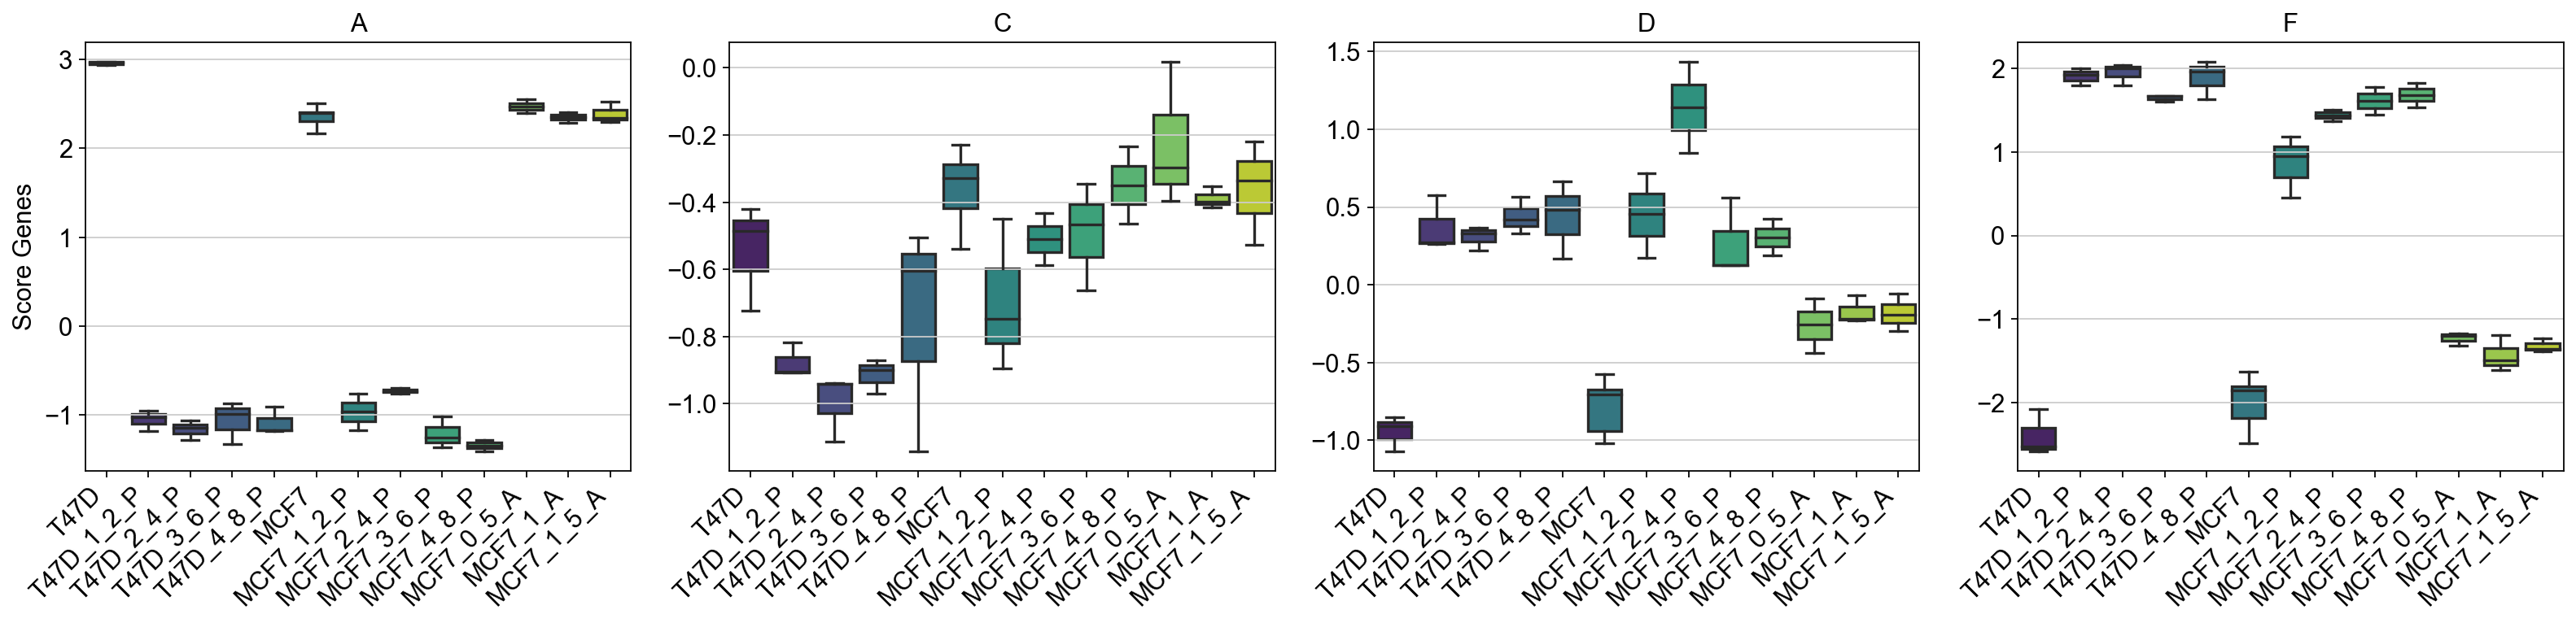

In [ ]:


fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

for i, var in enumerate(variables):
    sns.boxplot(
        data=adata.obs,
        x='Group', 
        y=var,
        order=[o for o in order if o in adata.obs['Group'].unique()],
        ax=axes[i],
        palette='viridis',
        fliersize=2  
    )
    axes[i].set_title(f'{var}', fontsize=14)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Score Genes' if i==0 else '')

plt.tight_layout()
plt.savefig("boxplots_individuales_firmas.png", dpi=300)
plt.show()

# GSE130437

In [ ]:
adata = sc.read_h5ad("Downloads/GSE130437_scRNAseq.h5ad")

In [ ]:
adata.obs

,Group,A,C,D,F,predicted_cluster,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,n_genes
GSM3738651,MCF7_res,1.068058,-1.096803,-0.738741,-0.891540,A,25435,10.143921,38016272.0,17.453526,21.348858,26.326145,32.786676,44.288217,0.0,0.0,0.0,25435
GSM3738652,MCF7_res,0.838967,-1.197887,-0.859164,-0.898664,A,25176,10.133686,33545462.0,17.328413,20.927689,25.721577,32.083678,43.603248,0.0,0.0,0.0,25176
GSM3738653,MCF7_res,1.067511,-1.487336,-0.720712,-0.892949,A,25233,10.135948,36141436.0,17.402950,22.056362,26.993811,33.460812,44.648334,0.0,0.0,0.0,25233
GSM3738654,MCF7,0.880207,0.431231,-1.224038,-0.843287,A,22728,10.031397,37298012.0,17.434450,15.043477,20.763718,28.021510,40.794761,0.0,0.0,0.0,22728
GSM3738655,MCF7,0.815083,0.181566,-1.216508,-0.848354,A,22642,10.027606,36297992.0,17.407272,14.936058,20.585935,27.854072,40.606935,0.0,0.0,0.0,22642
GSM3738656,MCF7,1.287010,0.589555,-1.144445,-0.841684,A,23309,10.056638,41850128.0,17.549606,14.224341,19.816771,27.066828,39.718187,0.0,0.0,0.0,23309
GSM3738657,MDAMB231_res,-0.959173,-0.276357,0.790274,1.393127,F,24532,10.107774,43819920.0,17.595598,14.562646,19.379170,25.860554,38.488669,0.0,0.0,0.0,24532
GSM3738658,MDAMB231_res,-0.960641,-0.414384,0.960859,1.582023,F,24827,10.119727,43682208.0,17.592451,13.863800,18.768449,25.404760,38.082807,0.0,0.0,0.0,24827
GSM3738659,MDAMB231_res,-0.961782,-0.716824,1.063306,1.708145,F,24737,10.116096,43522996.0,17.588800,13.931610,18.893938,25.639014,38.188697,0.0,0.0,0.0,24737
GSM3738660,MDAMB231,-1.027232,1.135572,0.948345,0.146426,C,21910,9.994744,39436384.0,17.490200,12.085314,17.366678,24.873361,38.427491,0.0,0.0,0.0,21910


In [ ]:
# 1. Calculate genes
for cluster_name, genes in cluster_genes.items():
    genes_in_data = [g for g in genes if g in adata.var_names]
    
    if len(genes_in_data) > 0:
        sc.tl.score_genes(adata, gene_list=genes_in_data, score_name=cluster_name)
    else:
        print(f"No genes {cluster_name}")

names_to_extract = [k for k in cluster_genes.keys() if k in adata.obs.columns]

# 3. Clasify
adata.obs['predicted_cluster'] = adata.obs[names_to_extract].idxmax(axis=1)

# 4. Margin
sorted_scores = adata.obs[names_to_extract].values.copy()
sorted_scores.sort(axis=1)
adata.obs['classification_margin'] = sorted_scores[:, -1] - sorted_scores[:, -2]

# --- verify ---
print(adata.obs[['predicted_cluster', 'classification_margin'] + names_to_extract].head())

           predicted_cluster  classification_margin         A         C  \
GSM3738651                 A               1.945172  2.079174 -0.387245   
GSM3738652                 A               1.999716  2.098320 -0.548632   
GSM3738653                 A               2.094617  2.158883 -0.426785   
GSM3738654                 A               1.961113  1.804771 -0.945879   
GSM3738655                 A               1.909608  1.831593 -0.985723   

                   D         F  
GSM3738651  0.134002 -0.880133  
GSM3738652  0.098604 -0.830477  
GSM3738653  0.064266 -0.731626  
GSM3738654 -0.156342 -1.480078  
GSM3738655 -0.078015 -1.491495  


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):
/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cu

In [ ]:
adata.obs['predicted_cluster'].value_counts()

A    6
F    6
Name: predicted_cluster, dtype: int64

In [ ]:
order = ['MCF7','MCF7_res','MDAMB231','MDAMB231_res']


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'predicted_cluster' as categorical


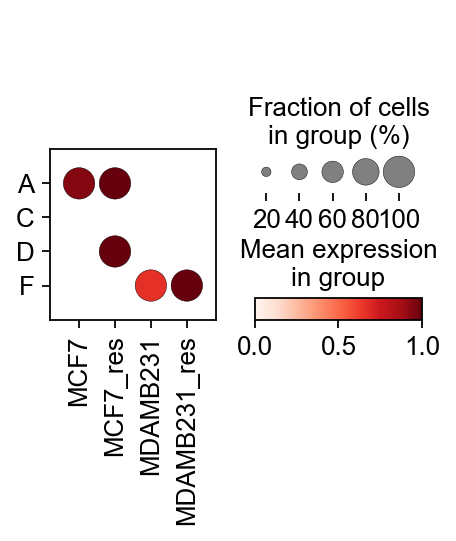

In [ ]:
variables = ['A','C','D','F']
sc.pl.dotplot(
    adata,
    var_names=variables,
    groupby="Group",swap_axes=True, 
    categories_order= order,
    gene_symbols=None,
    save="_dotplot_cdkpredict.png", standard_scale='var'
)

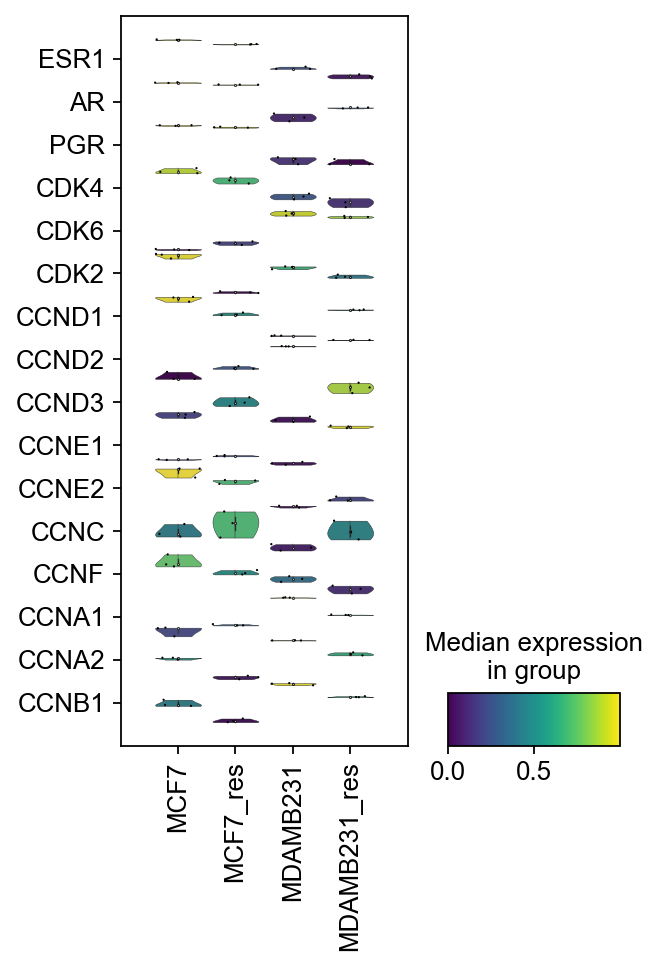

In [ ]:

genes_interes = [
    'ESR1', 'AR', 'PGR',                    
    'CDK4', 'CDK6', 'CDK2',                 
    'CCND1', 'CCND2', 'CCND3',              
    'CCNE1', 'CCNE2',                      
    'CCNC', 'CCNF',                         
    'CCNA1', 'CCNA2', 'CCNB1'              
]

sc.pl.stacked_violin(
    adata, 
    var_names=genes_interes, 
    groupby='Group', 
    categories_order=order,
    standard_scale='var',
    swap_axes=True,
    inner='boxplot',
    stripplot=True,           
    jitter=0.4,               
    size=1,                   
    ax=None,                  
    cmap='viridis',
    figsize=(4, 6),
    save="_violin_ciclinas_cdk_final.png"
)

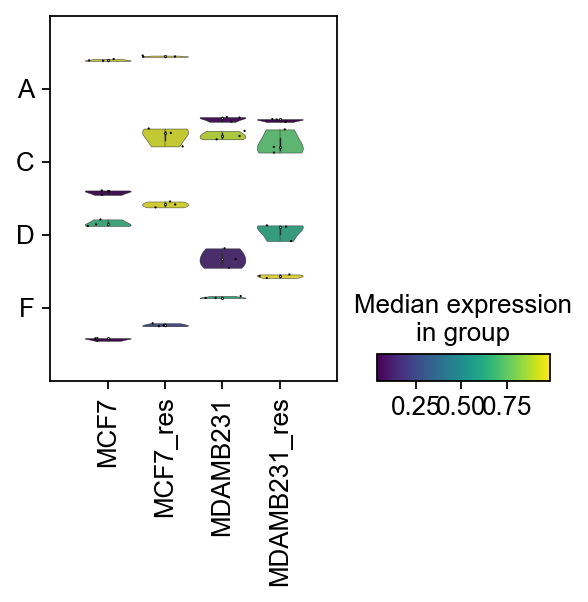

In [ ]:
sc.pl.stacked_violin(
    adata, 
    var_names=variables, 
    groupby='Group', 
    categories_order=order,
    standard_scale='var',
    swap_axes=True,
    inner='boxplot',
    stripplot=True,           
    jitter=0.4,               
    size=1,                   
    ax=None,                  
    cmap='viridis',
    figsize=(4, 6),
    save="_violin_ciclinas_cdk_final.png"
)

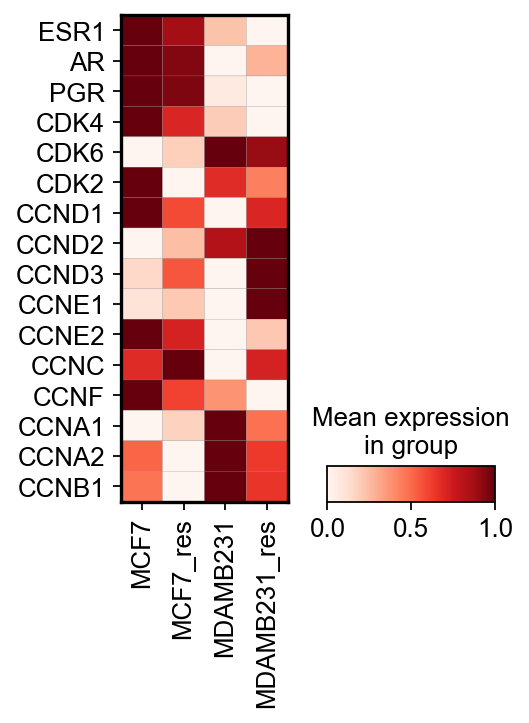

In [ ]:
sc.pl.matrixplot(
    adata, 
    var_names=genes_interes, 
    groupby='Group', 
    categories_order=order,
    use_raw=False,
    standard_scale='var', 
    cmap='Reds',
    figsize=(3, 4),
    swap_axes=True,
    save='test.png'
)

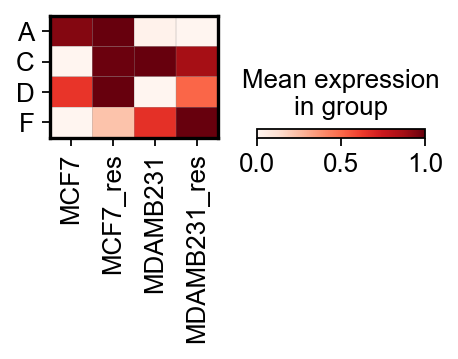

In [ ]:
sc.pl.matrixplot(
    adata, 
    var_names=variables, 
    groupby='Group', 
    categories_order=order,
    use_raw=False,
    standard_scale='var', 
    cmap='Reds',
    figsize=(3, 1),
    swap_axes=True,
    save='test.png'
)

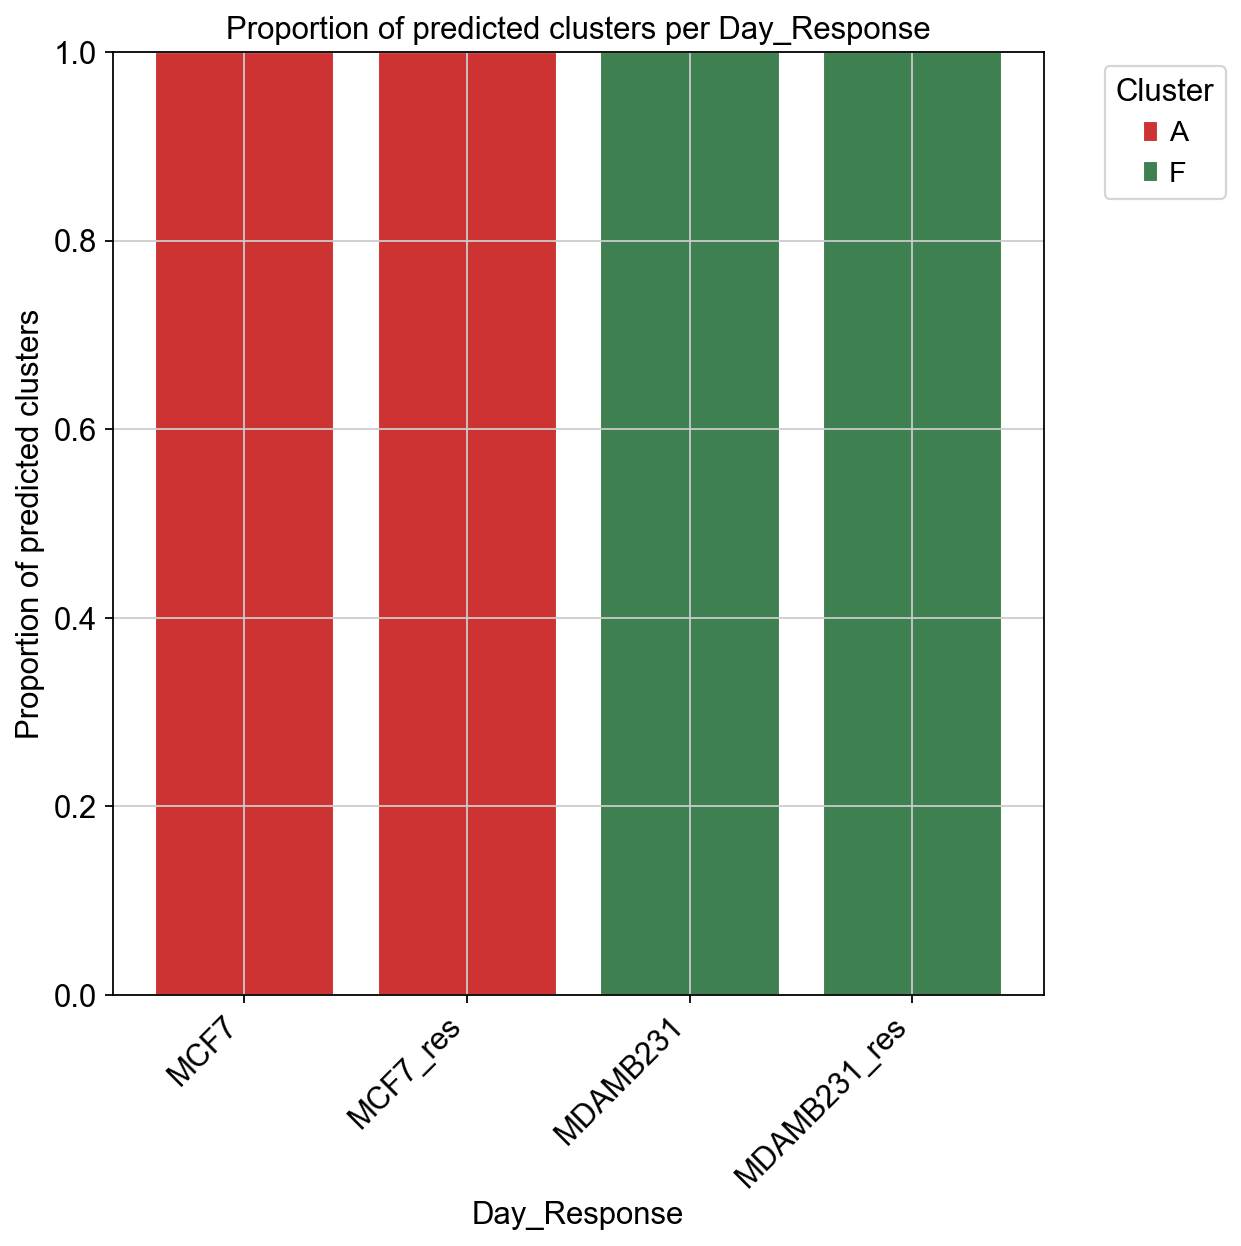

In [ ]:
# --- 1️⃣ Crear tabla de proporciones ---
prop_table = (
    adata.obs
    .groupby(['Group', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

# REORDENAR FILAS: Filtramos el vector order para incluir solo los que existen en la tabla
existing_order = [o for o in order if o in prop_table.index]
prop_table = prop_table.reindex(existing_order)

prop_table = (
    adata.obs
    .groupby(['Group', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

existing_order = [o for o in order if o in prop_table.index]
prop_table = prop_table.reindex(existing_order)

prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)


cluster_colors = {
    "A": "#CD3333",
    #"D": "#7A378B",
    "F": "#3E804F"
}

prop_table = prop_table[list(cluster_colors.keys())]


fig, ax = plt.subplots(figsize=(8, 8))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(
        x, 
        prop_table[cluster], 
        bottom=bottom, 
        color=cluster_colors[cluster], 
        label=cluster,
        edgecolor='white',
        linewidth=0.5
    )
    bottom += prop_table[cluster].values


ax.set_xticks(x)

ax.set_xticklabels(prop_table.index, rotation=45, ha='right') 
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Day_Response") 
ax.set_title("Proportion of predicted clusters per Day_Response")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_ordered.png", dpi=300)
plt.show()
# Convertir a proporción (que cada barra sume 100%)
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# --- 2️⃣ Definir colores para clusters ---
cluster_colors = {
    "A": "#CD3333",
    #"D": "#7A378B",
    "F": "#3E804F"
}

# Ordenar columnas para que coincida con colores (y solo los clusters que definiste)
prop_table = prop_table[list(cluster_colors.keys())]

# --- 3️⃣ Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(8, 8))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(
        x, 
        prop_table[cluster], 
        bottom=bottom, 
        color=cluster_colors[cluster], 
        label=cluster,
        edgecolor='white',
        linewidth=0.5
    )
    bottom += prop_table[cluster].values

# --- 4️⃣ Etiquetas y Estética ---
ax.set_xticks(x)
# Usamos el index de prop_table que ya está ordenado
ax.set_xticklabels(prop_table.index, rotation=45, ha='right') 
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Day_Response") # Actualizado el nombre
ax.set_title("Proportion of predicted clusters per Day_Response")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_ordered.png", dpi=300)
plt.show()

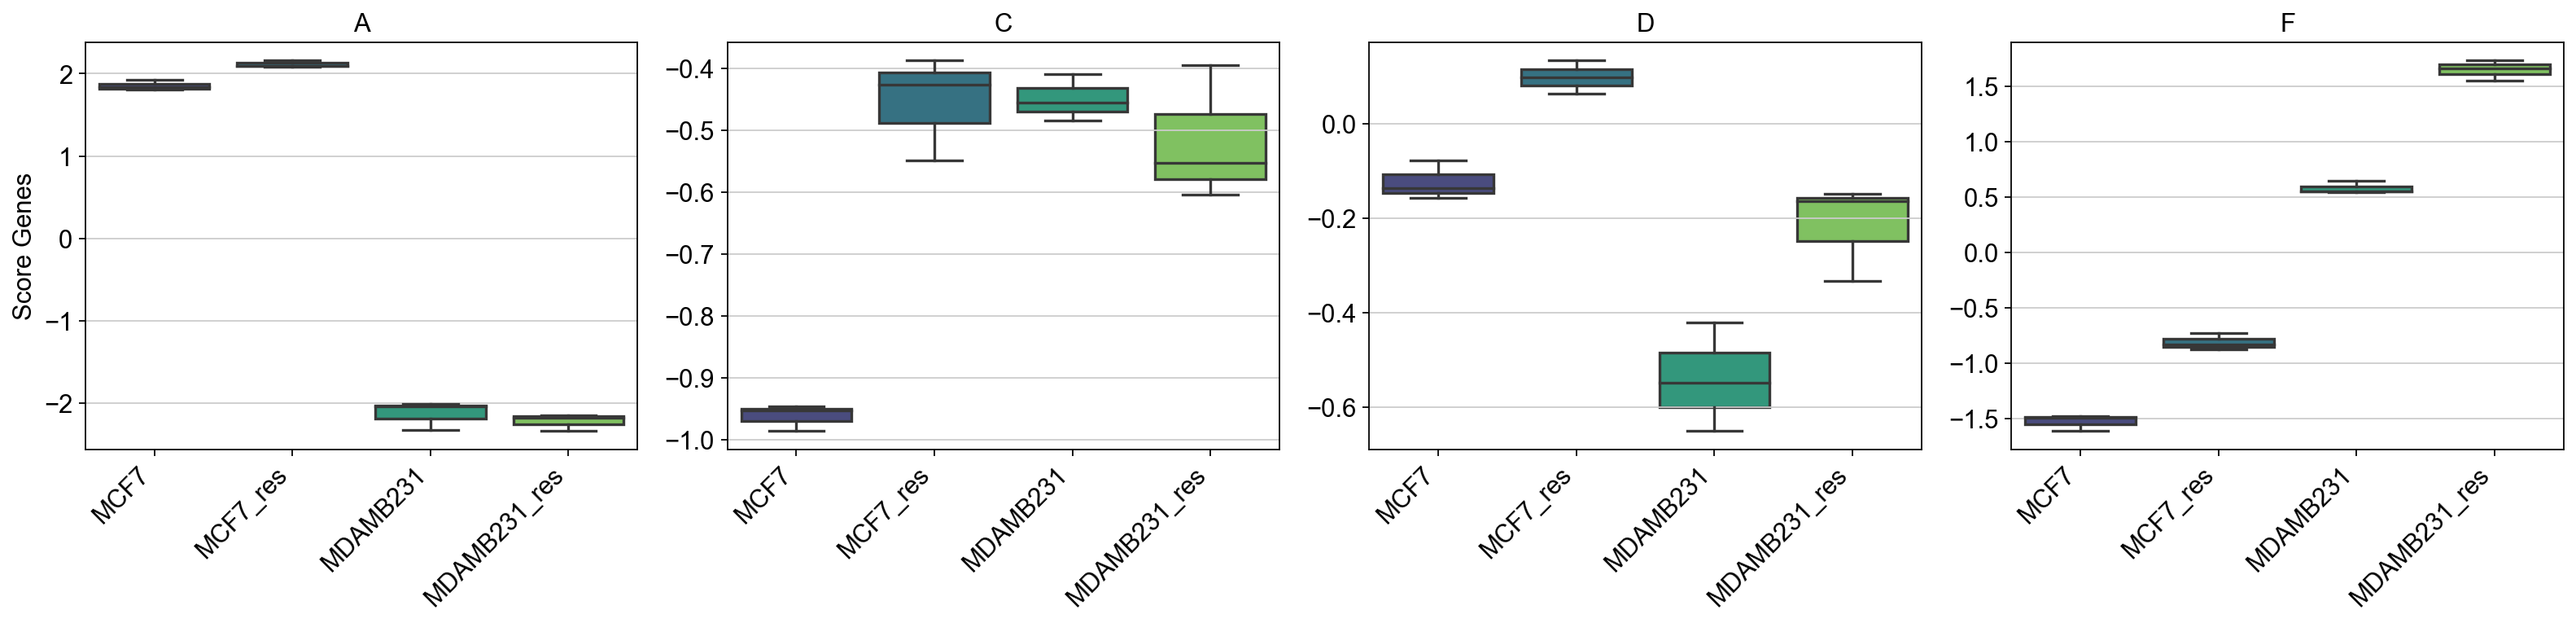

In [ ]:

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

for i, var in enumerate(variables):
    sns.boxplot(
        data=adata.obs,
        x='Group', 
        y=var,
        order=[o for o in order if o in adata.obs['Group'].unique()],
        ax=axes[i],
        palette='viridis',
        fliersize=2 
    )
    axes[i].set_title(f'{var}', fontsize=14)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Score Genes' if i==0 else '')

plt.tight_layout()
plt.savefig("boxplots_individuales_firmas.png", dpi=300)
plt.show()